In [1]:
# Basic tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import pickle

# UMAP and t-SNE
from umap import UMAP
from sklearn.manifold import TSNE

# Hierarchical clustering
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from matplotlib.legend_handler import HandlerTuple

mpl.rcParams['font.size'] = 12
mpl.rcParams['font.family'] = 'Arial'



In [2]:
# load the data
result_refseq = pickle.load(open("../Step4 ProstT5 Representation/cas12_refseq.pkl", "rb"))
result_discover = pickle.load(open("../Step4 ProstT5 Representation/AsCas12f_NR_s50.pkl", "rb"))

In [3]:
# retrieve data
repr_refseq = result_refseq["representations"]
repr_discover = result_discover["representations"]

label_refseq = result_refseq["labels"]
label_discover = result_discover["labels"]

sequence_refseq = result_refseq["sequences"]
sequence_discover = result_discover["sequences"]

print("Size of reference sequence: ", repr_refseq.shape)
print("Size of found sequence: ", repr_discover.shape)


Size of reference sequence:  (17, 1024)
Size of found sequence:  (17202, 1024)


In [4]:
merge_repr_discover = np.concatenate([repr_refseq, repr_discover])
merge_label_discover = np.concatenate([label_refseq, label_discover])
print(merge_repr_discover.shape)

(17219, 1024)


In [11]:
# hierarchical clustering
distance_matrix = pdist(merge_repr_discover, metric='euclidean')
linkage_matrix = linkage(distance_matrix, method='ward')

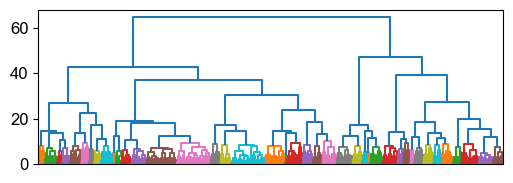

In [31]:
# create a dendrogram
THRESHOLD = 10
plt.figure(figsize=(6, 2))
tree_dict = dendrogram(linkage_matrix, color_threshold=THRESHOLD)
hierachy_cluster = fcluster(linkage_matrix, THRESHOLD, criterion='distance')

plt.xticks([])
plt.show()

In [32]:

def smoothsegment(seg, Nsmooth=100):
    """
    Smooths the transition between the middle two points of a segment by generating
    Nsmooth evenly spaced points between seg[1] (mid_start) and seg[2] (mid_end).
    The function returns an array that begins with seg[0] (start), includes the smoothed
    points, and ends with seg[3] (end).

    Parameters:
    - seg (array-like): An array of four values [start, mid_start, mid_end, end].
    - Nsmooth (int): The number of points to generate between seg[1] and seg[2]. Default is 100.

    Returns:
    - numpy.ndarray: A new array that starts with seg[0], includes the smoothed middle segment,
      and ends with seg[3].
    """
    return np.concatenate([[seg[0]], np.linspace(seg[1], seg[2], Nsmooth), [seg[3]]])


def smoothline(seg, Nsmooth=100):
    return np.linspace(seg[0], seg[1], Nsmooth)


def xcoord_to_ticks_rotation(xcoord):
    """
    Converts x coordinates to rotation angles for xticks.

    Parameters:
    - xcoord (numpy.ndarray): An array of x coordinates.

    Returns:
    - numpy.ndarray: An array of rotation angles for xticks.
    - str: A string indicating the alignment of the xticks.
    """
    if xcoord % (2*np.pi) <= 0.5*np.pi:
        return xcoord/np.pi*180, "left"
    elif xcoord % (2*np.pi) >= 1.5*np.pi:
        return xcoord/np.pi*180, "left"
    else:
        return (xcoord/np.pi*180-180), "right"


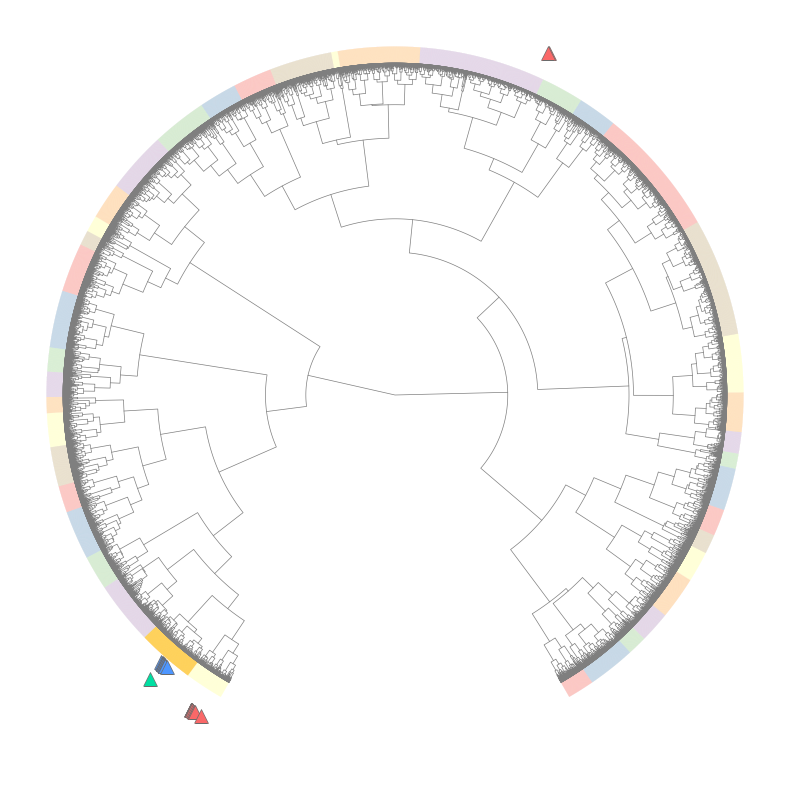

In [196]:
# rewrite the radial dendrogram
# load data
icoord = np.array(tree_dict['icoord'])
dcoord = np.array(tree_dict['dcoord'])
ivl = np.array(tree_dict['ivl'])
leaves = np.array(tree_dict['leaves'])
color_list = np.array(tree_dict['color_list'])
leaves_color_list = np.array(tree_dict['leaves_color_list'])

mapping_color = {
    "C0": "tab:grey",
    "C1": "tab:grey",
    "C2": "tab:grey",
    "C3": "tab:grey",
    "C4": "tab:grey",
    "C5": "tab:grey",
    "C6": "tab:grey",
    "C7": "tab:grey",
    "C8": "tab:grey",
    "C9": "tab:grey",
}



# convert the x coordinates to radians
gap = -1/3*np.pi
icoord = (icoord-icoord.min())/(icoord.max()-icoord.min())       # normalize the x coordinates to [0, 1]
icoord = icoord*5/6*2*np.pi+gap                                      # convert the normalized x coordinates to radians
# rescale the y coordinates
dcoord = -dcoord/dcoord.max()
# dcoord = -np.log2(dcoord+1)                                      # convert distance to log scale to make it more visually appealing

# get the x coordinates of the leaves
x_coord_leaves = np.linspace(0, 1, len(leaves))*5/6*2*np.pi+gap
# get the leave width
leave_width = 5/6*2*np.pi/len(leaves)


# start figure
plt.figure(figsize=(10,10))
plt.subplot(111, polar=True, rlabel_position=0)

# draw the radial dendrogram
for i in range(len(icoord)):
    xs = smoothsegment(icoord[i])
    ys = smoothsegment(dcoord[i])
    plt.plot(xs,ys, color=mapping_color[color_list[i]], linewidth=0.5)

# draw the ivl features
for i, idx_leave in enumerate(leaves):
    label = merge_label_discover[idx_leave]
    hierachy_cluster_id = hierachy_cluster[idx_leave]-1
    color_hierachy_cluster = plt.cm.Pastel1(hierachy_cluster_id%7)   # hierachy cluster
    plt.fill_between(x=smoothline([x_coord_leaves[i]-leave_width/2, x_coord_leaves[i]+leave_width/2]), 
                     y1=0., y2=0.05, color=color_hierachy_cluster, alpha=1, edgecolor="none")
    if idx_leave < len(label_refseq):
        if label_refseq[idx_leave] == "8J12-Cas12f":
            plt.scatter(x=x_coord_leaves[i], y=0.13, s=100, marker="^", color="#00DFA2", alpha=1, edgecolor="#6b6b6b", linewidth=0.5)
        elif label_refseq[idx_leave] in ['8bf8-TnpB', '8h1j-TnpB']:
            plt.scatter(x=x_coord_leaves[i], y=0.13, s=100, marker="^", color="#FA6868", alpha=1, edgecolor="#6b6b6b", linewidth=0.5)
        elif label_refseq[idx_leave] == "AcCas12n":
            pass
        else:
            plt.scatter(x=x_coord_leaves[i], y=0.13, s=100, marker="^", color="#FA6868", alpha=1, edgecolor="#6b6b6b", linewidth=0.5)
    else:
        if merge_label_discover[idx_leave] in [
                "DAG32506.1 ",
                "MBK7378306.1 ",
                "MBO5084694.1 ",
                "MBP5514557.1 ",
                "MBQ3269335.1 ",
                "MBQ9950927.1 ",
                "MBS5678475.1 ",
                "MBS6459277.1 ",
                "MCF7811397.1 ",
                "MCG4773868.1 ",
                "MCI7585022.1 ",
                "MCL2053139.1 ",
                "MCR5742295.1 ",
                "HAQ4723568.1 ",
                "PIE92697.1 ",
                "STO12739.1 ",
                "MBE5919695.1 "
            ]:
            plt.scatter(x=x_coord_leaves[i], y=0.07, s=100, marker="^", color="#4D96FF", alpha=1, edgecolor="#6b6b6b", linewidth=0.5)
    if hierachy_cluster_id == 40-1:
        plt.fill_between(x=smoothline([x_coord_leaves[i]-leave_width/2, x_coord_leaves[i]+leave_width/2]), 
                     y1=0., y2=0.05, color="#FFCC00", alpha=1, edgecolor="none")
        


# figure settings
plt.axis('off')
plt.grid(False)
plt.ylim(-1,0.16)
plt.yticks([])
plt.savefig("dendrogram.png", dpi=300, bbox_inches="tight")
plt.savefig("dendrogram.pdf")

plt.show()



In [195]:
df_ordered_labels = pd.DataFrame()

ordered_labels = merge_label_discover[leaves]
ordered_label_hierarchy_cluster = hierachy_cluster[leaves]
df_ordered_labels["label"] = ordered_labels
df_ordered_labels["hierarchy_cluster"] = ordered_label_hierarchy_cluster
df_ordered_labels.to_csv("ordered_labels.csv", index=False)


In [86]:
# calculate umap
umap = UMAP(
        n_neighbors=100,
        min_dist=0.1,
        n_components=2,
        metric='euclidean',
        spread=3,
    )
umap_results = umap.fit_transform(merge_repr_discover)


In [87]:
# create a dendrogram
THRESHOLD_high = 20
hierachy_cluster_less = fcluster(linkage_matrix, THRESHOLD_high, criterion='distance')
print(set(hierachy_cluster_less))

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}


In [ ]:
label_refseq
np.array([0,1,2,3,4,5,6,7,8,9,10,11,13,14,15])

['4oo8-SpCas9',
 '5u34-Cas12b1',
 '5x2g-CjCas9',
 '6M0W-StCas9',
 '6nme-Cas12a',
 '6w62-Cas12i',
 '6xmg-Cas12g',
 '7m5o-Cas12j',
 '7v93-Cas12c2',
 '7waz-Cas12e',
 '8bf8-TnpB',
 '8dc2-Cas12l',
 '8h1j-TnpB',
 '8pm4-Cas12m',
 '8J12-Cas12f',
 '8gkh-SpuFz',
 'AcCas12n']

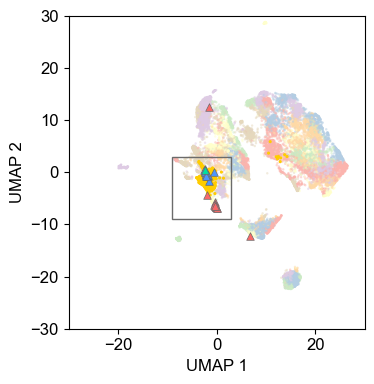

In [198]:
selected_candidates_ids = [
    "DAG32506.1 ",
    "MBK7378306.1 ",
    "MBO5084694.1 ",
#     "MBP5514557.1 ",
    "MBQ3269335.1 ",
    "MBQ9950927.1 ",
    "MBS5678475.1 ",
    "MBS6459277.1 ",
    "MCF7811397.1 ",
    "MCG4773868.1 ",
    "MCI7585022.1 ",
    "MCL2053139.1 ",
    "MCR5742295.1 ",
    "HAQ4723568.1 ",
    "PIE92697.1 ",
    "STO12739.1 ",
    "MBE5919695.1 "
]
selected_idxs = np.array([np.where(merge_label_discover == id)[0][0] for id in selected_candidates_ids])



fig = plt.figure(figsize=(4, 4))
ax1 = plt.subplot(1,1,1)

# ax1: source
ax1.scatter(umap_results[:, 0], 
            umap_results[:, 1], 
            color=plt.cm.Pastel1((hierachy_cluster-1)%7),
            s=3, alpha=0.5, edgecolor="None")


ax1.scatter(umap_results[:, 0][hierachy_cluster == 40], 
            umap_results[:, 1][hierachy_cluster == 40], 
            color="#FFCC00", label="Selected cluster",
            s=5, alpha=1, edgecolor="None")

ax1.scatter(umap_results[np.array([0,1,2,3,4,5,6,7,8,9,10,11,13,14,15]), 0], 
            umap_results[np.array([0,1,2,3,4,5,6,7,8,9,10,11,13,14,15]), 1], 
            color="#FA6868", label="Other Cas",
            marker="^",
            s=30, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)

        
ax1.scatter(umap_results[selected_idxs, 0], 
            umap_results[selected_idxs, 1], 
            color="#4D96FF", label="Candidates",
            marker="^",
            s=30, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)

ax1.scatter(umap_results[14, 0], 
            umap_results[14, 1], 
            color="#00DFA2", label="AsCas12f",
            marker="^",
            s=30, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)

# add a rectangle
rect = plt.Rectangle((-9, -9), 12, 12, fill=False, edgecolor="#6b6b6b", linewidth=1)
ax1.add_patch(rect)

ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
ax1.set_xlim(-30, 30)
ax1.set_ylim(-30, 30)

fig.tight_layout()
fig.savefig("umap.png", dpi=300, bbox_inches="tight")

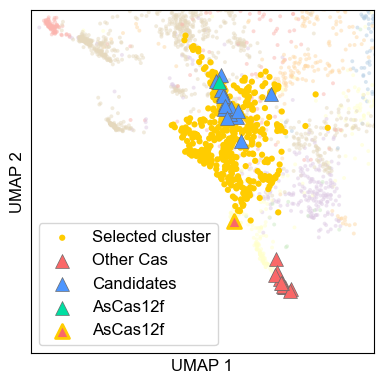

In [200]:
selected_candidates_ids = [
    "DAG32506.1 ",
    "MBK7378306.1 ",
    "MBO5084694.1 ",
#     "MBP5514557.1 ",
    "MBQ3269335.1 ",
    "MBQ9950927.1 ",
    "MBS5678475.1 ",
    "MBS6459277.1 ",
    "MCF7811397.1 ",
    "MCG4773868.1 ",
    "MCI7585022.1 ",
    "MCL2053139.1 ",
    "MCR5742295.1 ",
    "HAQ4723568.1 ",
    "PIE92697.1 ",
    "STO12739.1 ",
    "MBE5919695.1 "
]
selected_idxs = np.array([np.where(merge_label_discover == id)[0][0] for id in selected_candidates_ids])



fig = plt.figure(figsize=(4, 4))
ax1 = plt.subplot(1,1,1)

# ax1: source
ax1.scatter(umap_results[:, 0], 
            umap_results[:, 1], 
            color=plt.cm.Pastel1((hierachy_cluster-1)%7),
            s=8, alpha=0.5, edgecolor="None")


ax1.scatter(umap_results[:, 0][hierachy_cluster == 40], 
            umap_results[:, 1][hierachy_cluster == 40], 
            color="#FFCC00", label="Selected cluster",
            s=20, alpha=1, edgecolor="None")

ax1.scatter(umap_results[np.array([0,1,2,3,4,5,6,7,8,9,10,11,13,14,15]), 0], 
            umap_results[np.array([0,1,2,3,4,5,6,7,8,9,10,11,13,14,15]), 1], 
            color="#FA6868", label="Other Cas",
            marker="^",
            s=100, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)

        
ax1.scatter(umap_results[selected_idxs, 0], 
            umap_results[selected_idxs, 1], 
            color="#4D96FF", label="Candidates",
            marker="^",
            s=100, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)

ax1.scatter(umap_results[14, 0], 
            umap_results[14, 1], 
            color="#00DFA2", label="AsCas12f",
            marker="^",
            s=100, alpha=1, edgecolor="#6b6b6b", linewidth=0.5)


ax1.scatter(umap_results[13, 0], 
            umap_results[13, 1], 
            color="#FA6868", label="AsCas12f",
            marker="^",
            s=100, alpha=1, edgecolor="#FFCC00", linewidth=2)


ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
ax1.set_xlim(-9, 3)
ax1.set_ylim(-9, 3)
ax1.set_xticks([])
ax1.set_yticks([])

ax1.legend(loc="lower left")

fig.tight_layout()
fig.savefig("umap_detail.png", dpi=300, bbox_inches="tight")